In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, kurtosis, norm, t

In [2]:
df = pd.read_csv('https://raw.githubusercontent.com/alura-cursos/projeto-logistica-eLura/refs/heads/main/e_lura_vendas_logistica.csv')

In [3]:
df.head()

,ID_Cliente,Data_Compra,Valor_Total,Qtd_Itens,Categoria_Produto,Regiao_Cliente,Tempo_Entrega_Dias,Entrega_Atrasada,Avaliacao_Produto,Satisfacao_Logistica,Cancelamento
0,CLI_00001,2024-09-11,72.94,2,Eletrônicos,Sul,2.9,Não,5.0,3,Sim
1,CLI_00002,2025-08-10,11.81,5,Livros,Sudeste,4.6,Sim,5.0,1,Sim
2,CLI_00003,2025-02-26,55.05,1,Eletrônicos,Sudeste,1.5,Não,3.0,4,Não
3,CLI_00004,2024-09-15,55.02,1,Eletrônicos,Sudeste,3.1,Não,4.0,5,Não
4,CLI_00005,2024-08-11,52.63,3,Eletrônicos,Sul,3.3,Não,1.0,5,Não


In [4]:
# Informações da dimensão das tabelas
df.shape

(100000, 11)

In [5]:
# Informação das colunas
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 11 columns):
 #   Column                Non-Null Count   Dtype  
---  ------                --------------   -----  
 0   ID_Cliente            100000 non-null  str    
 1   Data_Compra           100000 non-null  str    
 2   Valor_Total           100000 non-null  float64
 3   Qtd_Itens             100000 non-null  int64  
 4   Categoria_Produto     100000 non-null  str    
 5   Regiao_Cliente        100000 non-null  str    
 6   Tempo_Entrega_Dias    100000 non-null  float64
 7   Entrega_Atrasada      100000 non-null  str    
 8   Avaliacao_Produto     98000 non-null   float64
 9   Satisfacao_Logistica  100000 non-null  int64  
 10  Cancelamento          100000 non-null  str    
dtypes: float64(3), int64(2), str(6)
memory usage: 8.4 MB


In [6]:
# Descrições estatísticas das colunas numéricas
df.describe()

,Valor_Total,Qtd_Itens,Tempo_Entrega_Dias,Avaliacao_Produto,Satisfacao_Logistica
count,100000.000000,100000.000000,100000.000000,98000.000000,100000.000000
mean,82.050995,2.404470,3.681881,3.599888,3.430880
std,59.101375,1.389206,2.712932,1.068316,1.481703
min,3.640000,1.000000,0.500000,1.000000,1.000000
25%,42.977500,1.000000,1.700000,3.000000,2.000000
50%,66.480000,2.000000,3.200000,4.000000,4.000000
75%,103.110000,3.000000,4.900000,4.000000,5.000000
max,1340.600000,11.000000,24.000000,5.000000,5.000000


In [7]:
# Visualizando valores únicos de algumas variáveis categóricas chave

cat_cols = ["Categoria_Produto", "Regiao_Cliente", "Entrega_Atrasada", "Cancelamento"]
for col in cat_cols:
    print(f"\nColuna: {col}")
    print(df[col].value_counts())


Coluna: Categoria_Produto
Categoria_Produto
Moda             30073
Eletrônicos      24988
Livros           15002
Alimentos        11955
Casa e Jardim    10054
Esporte           7928
Name: count, dtype: int64

Coluna: Regiao_Cliente
Regiao_Cliente
Sudeste         39722
Sul             24818
Nordeste        20259
Centro-Oeste    10065
Norte            5136
Name: count, dtype: int64

Coluna: Entrega_Atrasada
Entrega_Atrasada
Não    67813
Sim    32187
Name: count, dtype: int64

Coluna: Cancelamento
Cancelamento
Não    76434
Sim    23566
Name: count, dtype: int64


In [8]:
print("\n" + "=" * 60)
print("FEATURRE ENGINEERING - TRANSFORMANDO DADOS")
print("=" * 60)

# EXEMPLO 1: Dados estruturados -> Novas Features
print("\n 1 FEATURE ENGINEERING EM DADOS ESTRUTURADOS")
print("--" * 60)

# Criar novas features a partir das existentes
df['ticket_medio'] = df['Valor_Total'] / df['Qtd_Itens']
df['Data_Compra'] = pd.to_datetime(df['Data_Compra'])
df['mes'] = df['Data_Compra'].dt.month
df['dia_semana'] = df['Data_Compra'].dt.day_name()
df['valor_categoria'] = pd.cut(df['Valor_Total'],
                               bins=[0, 100, 300, 1000],
                               labels=['baixo', 'médio', 'alto'])

print("\nDataset com novas features:")
print(df[['Data_Compra', 'ticket_medio', 'mes', 'dia_semana', 'valor_categoria']])


FEATURRE ENGINEERING - TRANSFORMANDO DADOS

 1 FEATURE ENGINEERING EM DADOS ESTRUTURADOS
------------------------------------------------------------------------------------------------------------------------

Dataset com novas features:
      Data_Compra  ticket_medio  mes dia_semana valor_categoria
0      2024-09-11     36.470000    9  Wednesday           baixo
1      2025-08-10      2.362000    8     Sunday           baixo
2      2025-02-26     55.050000    2  Wednesday           baixo
3      2024-09-15     55.020000    9     Sunday           baixo
4      2024-08-11     17.543333    8     Sunday           baixo
...           ...           ...  ...        ...             ...
99995  2025-10-06     14.153333   10     Monday           baixo
99996  2025-10-02     39.855000   10   Thursday           baixo
99997  2025-07-01     33.430000    7    Tuesday           baixo
99998  2025-10-14     19.245000   10    Tuesday           baixo
99999  2025-10-16     46.050000   10   Thursday         

In [9]:
# EXEMPLO 2: Texto -> Features Numéricas
print("\n��‍�� FEATURE ENGINEERING EM TEXTO")
print("=" * 60)

reviews = [
    "Produto excelente! Chegou rápido e bem embalado. Recomendo!",
    "Decepcionante. Qualidade inferior ao esperado.",
    "Produto OK. Nada excepcional, mas funciona.",
    "Adorei! Superou minhas expectativas!",
    "Não recomendo. Defeito no recebimento."
]

print("Reviews brutos (não estruturados):")
for review in reviews:
  print(f" \"{review}\"")

# Extrair features de texto
features_texto = []

palavras_positivas = ['excelente', 'adorei', 'recomendo', 'superou']
palavras_negativas = ['decepcionante', 'defeito', 'inferior', 'não']

for review in reviews:
    review_lower = review.lower()

    # Features extraídas
    n_palavras = len(review_lower.split())
    n_pontuacao = review.count('!') + review.count('?')
    n_positivas = sum(1 for palavra in palavras_positivas if palavra in review_lower)
    n_negativas = sum(1 for palavra in palavras_negativas if palavra in review_lower)
    sentimento = 'positivo' if n_positivas > n_negativas else ('negativo' if n_negativas > n_positivas else 'neutro')

    features_texto.append({
        'review': review[:40] + '...',
        'n_palavras': n_palavras,
        'n_pontuacao': n_pontuacao,
        'palavras_pos': n_positivas,
        'palavras_neg': n_negativas,
        'sentimento': sentimento
    })

df_reviews = pd.DataFrame(features_texto)

print("\nFeatures extraídas (estruturado):")
print(df_reviews)


��‍�� FEATURE ENGINEERING EM TEXTO
Reviews brutos (não estruturados):
 "Produto excelente! Chegou rápido e bem embalado. Recomendo!"
 "Decepcionante. Qualidade inferior ao esperado."
 "Produto OK. Nada excepcional, mas funciona."
 "Adorei! Superou minhas expectativas!"
 "Não recomendo. Defeito no recebimento."

Features extraídas (estruturado):
                                        review  n_palavras  n_pontuacao  \
0  Produto excelente! Chegou rápido e bem e...           8            2   
1  Decepcionante. Qualidade inferior ao esp...           5            0   
2  Produto OK. Nada excepcional, mas funcio...           6            0   
3      Adorei! Superou minhas expectativas!...           4            2   
4    Não recomendo. Defeito no recebimento....           5            0   

   palavras_pos  palavras_neg sentimento  
0             2             0   positivo  
1             0             2   negativo  
2             0             0     neutro  
3             2             0

In [10]:
# EXEMPLO 3: Imagem -> Features Estatísticas
print("\n��‍�� FEATURE ENGINEERING EM IMAGEM")
print("=" * 60)
# Criar imagens simples para demonstração
from PIL import Image, ImageDraw

# Imagem 1: Padrão clara
img1 = Image.new('RGB', (100, 100), color='white')
draw = ImageDraw.Draw(img1)
for i in range(0, 100, 10):
    draw.line([(i, 0), (i, 100)], fill='black', width=1)

# Imagem 2: Padrão escura
img2 = Image.new('RGB', (100, 100), color='black')

# Converter para arrays numpy
arr_clara = np.array(img1)
arr_escura = np.array(img2)

print("Imagem 1 (clara com linhas):")
print(f"  Shape: {arr_clara.shape}")
print(f"  Pixel [50,50]: {arr_clara[50, 50]}")

print("\nImagem 2 (escura):")
print(f"  Shape: {arr_escura.shape}")
print(f"  Pixel [50,50]: {arr_escura[50, 50]}")

def extrair_features_imagem(arr):
    """Extrai features estatísticas de uma imagem"""
    # Converter para escala de cinza (média dos 3 canais RGB)
    gray = np.mean(arr, axis=2)

    features = {
        'luminosidade_media': np.mean(gray),
        'contraste_std': np.std(gray),
        'brilho_max': np.max(gray),
        'escuridao_min': np.min(gray),
        'histograma_bimodal': len(np.unique(gray)) > 50
    }
    return features

features_img1 = extrair_features_imagem(arr_clara)
features_img2 = extrair_features_imagem(arr_escura)

print("\nFeatures extraídas de imagens (estruturado):")

print("\nImagem 1 (clara):")
for chave, valor in features_img1.items():
    print(f"  {chave}: {valor}")

print("\nImagem 2 (escura):")
for chave, valor in features_img2.items():
    print(f"  {chave}: {valor}")

print("\nAgora podemos comparar estatisticamente:")
print(f"  Diferença de luminosidade: {abs(features_img1['luminosidade_media'] - features_img2['luminosidade_media']):.2f}")


��‍�� FEATURE ENGINEERING EM IMAGEM


Imagem 1 (clara com linhas):
  Shape: (100, 100, 3)
  Pixel [50,50]: [0 0 0]

Imagem 2 (escura):
  Shape: (100, 100, 3)
  Pixel [50,50]: [0 0 0]

Features extraídas de imagens (estruturado):

Imagem 1 (clara):
  luminosidade_media: 229.5
  contraste_std: 76.5
  brilho_max: 255.0
  escuridao_min: 0.0
  histograma_bimodal: False

Imagem 2 (escura):
  luminosidade_media: 0.0
  contraste_std: 0.0
  brilho_max: 0.0
  escuridao_min: 0.0
  histograma_bimodal: False

Agora podemos comparar estatisticamente:
  Diferença de luminosidade: 229.50


In [11]:
# Criar uma "amostra" de 20% dos pedidos
amostra = df.sample(frac=0.2, random_state=42)

In [12]:
print(df.shape)
print(amostra.shape)

(100000, 15)
(20000, 15)


In [13]:
# Comparar médias populacionais x amostrais
print("Média populacional de Tempo_Entrega:", df['Tempo_Entrega_Dias'].mean())
print("Média amostral de Tempo_Entrega:", amostra['Tempo_Entrega_Dias'].mean())

Média populacional de Tempo_Entrega: 3.6818809999999997
Média amostral de Tempo_Entrega: 3.6703650000000003


In [14]:
cols_focus = ['Valor_Total', 'Tempo_Entrega_Dias']

for col in cols_focus:
    print(f"\n=== {col} ===")
    print(f"Média  : {df[col].mean():.2f}")
    print(f"Mediana: {df[col].median():.2f}")
    print(f"Modas  : {df[col].mode()}")


=== Valor_Total ===
Média  : 82.05
Mediana: 66.48
Modas  : 0    36.82
1    41.40
2    49.28
3    50.94
4    52.35
5    55.46
Name: Valor_Total, dtype: float64

=== Tempo_Entrega_Dias ===
Média  : 3.68
Mediana: 3.20
Modas  : 0    1.5
Name: Tempo_Entrega_Dias, dtype: float64


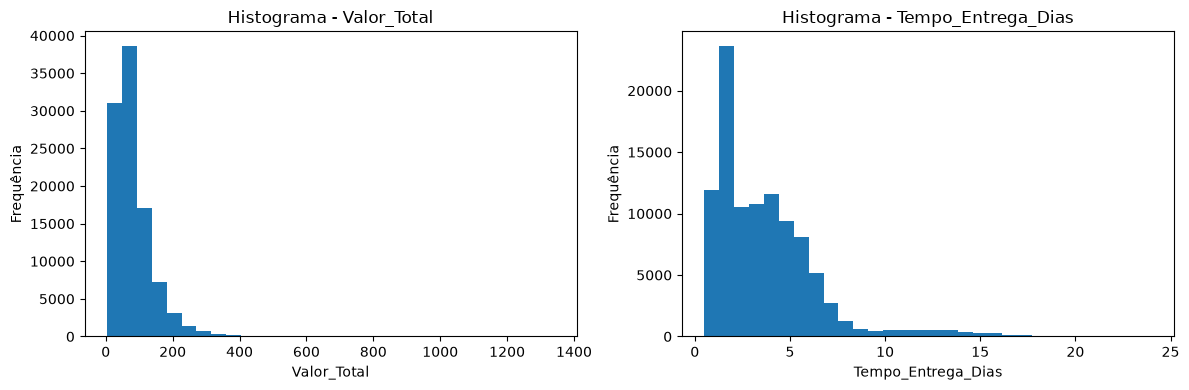

In [15]:
# Visualizando a distribuição básica de Valor_Total e Tempo_Entrega_Dias

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(df['Valor_Total'], bins=30)
axes[0].set_title('Histograma - Valor_Total')
axes[0].set_xlabel('Valor_Total')
axes[0].set_ylabel('Frequência')

axes[1].hist(df['Tempo_Entrega_Dias'], bins=30)
axes[1].set_title('Histograma - Tempo_Entrega_Dias')
axes[1].set_xlabel('Tempo_Entrega_Dias')
axes[1].set_ylabel('Frequência')

plt.tight_layout()
plt.show()

In [16]:
tempo = df['Tempo_Entrega_Dias']

q1 = tempo.quantile(0.25)
q2 = tempo.quantile(0.50)
q3 = tempo.quantile(0.75)

q1, q2, q3

(np.float64(1.7), np.float64(3.2), np.float64(4.9))

/tmp/ipykernel_10522/3850449515.py:2: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(tempo, vert=True)


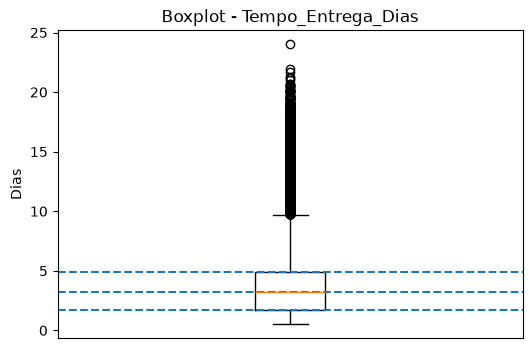

In [17]:
plt.figure(figsize=(6,4))
plt.boxplot(tempo, vert=True)

plt.axhline(q1, linestyle='--')
plt.axhline(q2, linestyle='--')
plt.axhline(q3, linestyle='--')

plt.title("Boxplot - Tempo_Entrega_Dias")
plt.ylabel('Dias')
plt.xticks([])
plt.show()

In [18]:
tempo = df['Tempo_Entrega_Dias'].dropna()

# Amplitude total
min_tempo = tempo.min()
max_tempo = tempo.max()
amplitude = max_tempo - min_tempo

print(f'Mínimo: {min_tempo}')
print(f'Máximo: {max_tempo}')
print(f'Amplitude total: {amplitude}')

Mínimo: 0.5
Máximo: 24.0
Amplitude total: 23.5


In [19]:
valor = df['Valor_Total'].dropna()

# Amplitude total
min_valor = valor.min()
max_valor = valor.max()
amplitude = max_valor - min_valor

print(f'Mínimo: {min_valor}')
print(f'Máximo: {max_valor}')
print(f'Amplitude total: {amplitude}')

Mínimo: 3.64
Máximo: 1340.6
Amplitude total: 1336.9599999999998


In [20]:
q1 = valor.quantile(0.25)
q2 = valor.quantile(0.50) # mediana
q3 = valor.quantile(0.75)

iqr = q3 - q1

print(f'Q1 (25%): {q1}')
print(f'Q2 (50%, mediana): {q2}')
print(f'Q3 (75%): {q3}')
print(f'IQR (Q3 - Q1): {iqr}')

Q1 (25%): 42.9775
Q2 (50%, mediana): 66.48
Q3 (75%): 103.11
IQR (Q3 - Q1): 60.1325


In [21]:
# Outliers (método Tukey)

limite_inf = q1 - 1.5 * iqr
limite_sup = q3 + 1.5 * iqr
outliers = ((valor < limite_inf) | (valor > limite_sup))

outliers

0        False
1        False
2        False
3        False
4        False
         ...  
99995    False
99996    False
99997    False
99998    False
99999    False
Name: Valor_Total, Length: 100000, dtype: bool

In [22]:
outliers.value_counts()

Valor_Total
False    95007
True      4993
Name: count, dtype: int64

Text(103.11, 25663.060499999996, 'Q3 (75%)')

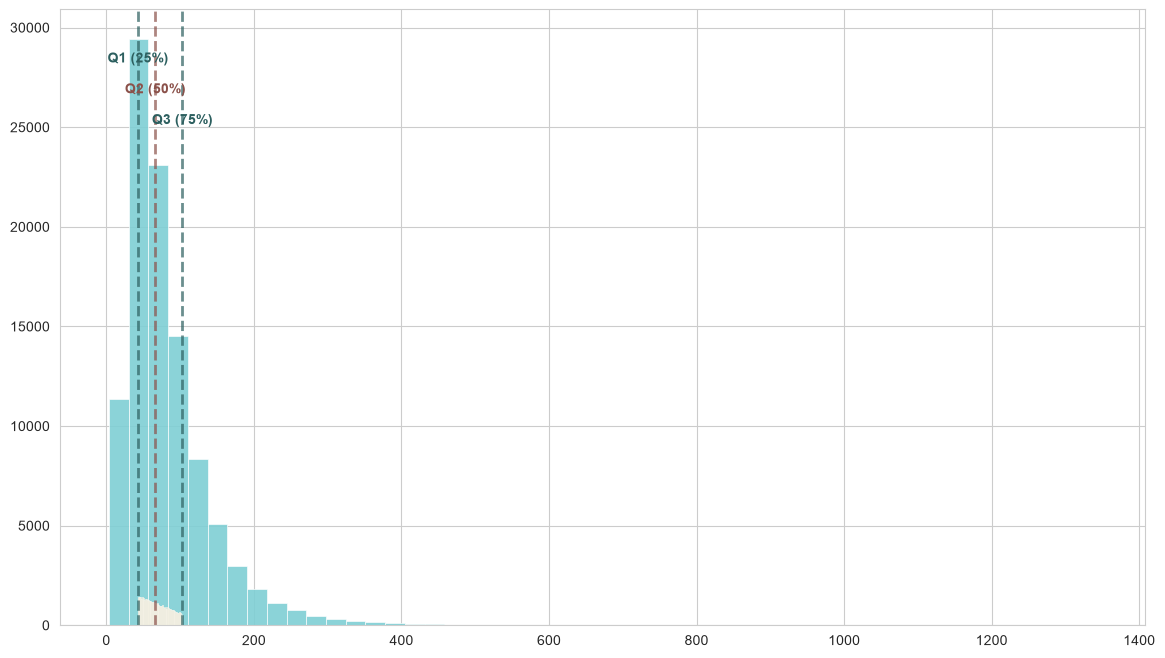

In [23]:
# Série de interesse
valor = df['Valor_Total'].dropna()

# Calcular quartis (Q1, Q2, Q3) e IQR
q1 = np.percentile(valor, 25)
q2 = np.percentile(valor, 50) # mediana
q3 = np.percentile(valor, 75)
iqr = q3 - q1

# Configurar o estilo do gráfico
sns.set_style('whitegrid')
plt.figure(figsize=(14,8))

# 3. Histograma completo (toda a distribuição)
bins = 50
plt.hist(
    valor,
    bins=bins,
    color="#7FCFD4",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.9,
    label="Distribuição completa",
)

# 4. Histograma apenas do IQR (50% central)
data_iqr = valor[(valor > q1) & (valor <= q3)]
plt.hist(
    data_iqr,
    bins=bins,
    color="#C9B571",
    edgecolor="white",
    linewidth=0.5,
    alpha=0.9,
    label="IQR (50% central)",
)

# 5. Linhas verticais Q1, Q2, Q3
plt.axvline(q1, color="#2C5F5F", linestyle='--', linewidth=2, alpha=0.7)
plt.axvline(q2, color="#8B514A", linestyle='--', linewidth=2, alpha=0.7)
plt.axvline(q3, color="#2C5F5F", linestyle='--', linewidth=2, alpha=0.7)

# 6. Rótulos dos quartis em alturas diferentes (para não sobrepor)
y_max = plt.ylim()[1]

plt.text(
    q1,
    y_max * 0.93,
    "Q1 (25%)",
    ha="center",
    va="top",
    fontsize=10,
    color="#2C5F5F",
    weight="bold"
)
plt.text(
    q2,
    y_max * 0.88,
    "Q2 (50%)",
    ha="center",
    va="top",
    fontsize=10,
    color="#8B514A",
    weight="bold"
)
plt.text(
    q3,
    y_max * 0.83,
    "Q3 (75%)",
    ha="center",
    va="top",
    fontsize=10,
    color="#2C5F5F",
    weight="bold"
)

In [24]:
for col in ['Tempo_Entrega_Dias', 'Valor_Total']:
    serie = df[col].dropna()
    print(f'\n=== {col} ===')
    print(f'Média: {serie.mean():.2f}')
    print(f'Variância: {serie.var():.2f}')
    print(f'Desv. Padr.: {serie.std():.2f}')


=== Tempo_Entrega_Dias ===
Média: 3.68
Variância: 7.36
Desv. Padr.: 2.71

=== Valor_Total ===
Média: 82.05
Variância: 3492.97
Desv. Padr.: 59.10


In [25]:
for col in ['Tempo_Entrega_Dias', 'Valor_Total']:
    serie = df[col].dropna()

    skewness_pandas = serie.skew()
    skewness_scipy = skew(serie, bias=False) # bias=False usa o estimador sem viés

    if skewness_pandas > 0.5:
        direcao = 'DIREITA (positiva)'
    elif skewness_pandas < -0.5:
        direcao = 'ESQUERDA (negativa)'
    else:
        direcao = 'APROXIMADAMENTE SIMÉTRICA'

    print(f'\n{col}')
    print("-" * 80)
    print(f'Skewness (pandas): {skewness_pandas:.4f}')
    print(f'Skewness (scipy): {skewness_scipy:.4f}')
    print(f'Direção: {direcao}')
    print(f'Média: {serie.mean():.2f}')
    print(f'Mediana: {serie.median():.2f}')
    print(f'Moda (aproximada): {serie.mode().values[0] if len(serie.mode()) > 0 else 'N/A'}')


Tempo_Entrega_Dias
--------------------------------------------------------------------------------
Skewness (pandas): 1.9212
Skewness (scipy): 1.9212
Direção: DIREITA (positiva)
Média: 3.68
Mediana: 3.20
Moda (aproximada): 1.5

Valor_Total
--------------------------------------------------------------------------------
Skewness (pandas): 2.4810
Skewness (scipy): 2.4810
Direção: DIREITA (positiva)
Média: 82.05
Mediana: 66.48
Moda (aproximada): 36.82


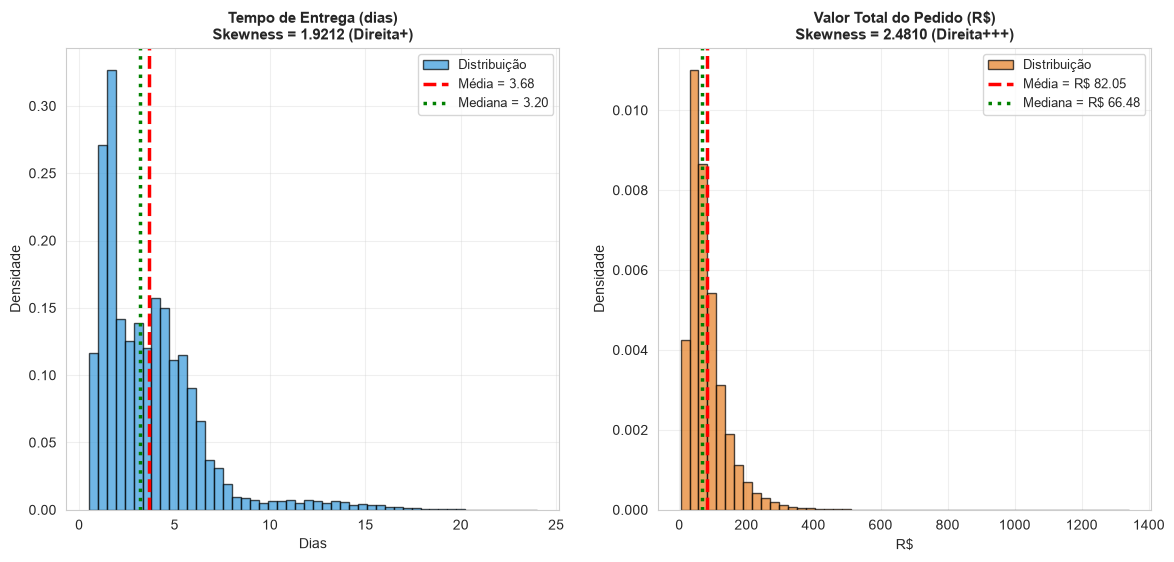

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# (a) Tempo de entrega
axes[0].hist(
    tempo,
    bins=50,
    color="#3498db",
    edgecolor="black",
    alpha=0.7,
    density=True,
    label="Distribuição",
)

media_tempo = tempo.mean()
mediana_tempo = tempo.median()
skew_tempo = tempo.skew()

axes[0].axvline(media_tempo, color="red", linestyle="--", linewidth=2.5,
              label=f"Média = {media_tempo:.2f}")
axes[0].axvline(mediana_tempo, color="green", linestyle=":", linewidth=2.5,
              label=f"Mediana = {mediana_tempo:.2f}")
axes[0].set_title(f"Tempo de Entrega (dias)\nSkewness = {skew_tempo:.4f} (Direita+)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Dias")
axes[0].set_ylabel("Densidade")
axes[0].legend(fontsize=9)
axes[0].grid(alpha=0.3)

# (b) Valor total
axes[1].hist(
    valor,
    bins=50,
    color="#e67e22",
    edgecolor="black",
    alpha=0.7,
    density=True,
    label="Distribuição",
)

media_valor = valor.mean()
mediana_valor = valor.median()
skew_valor = valor.skew()

axes[1].axvline(media_valor, color="red", linestyle="--", linewidth=2.5,
              label=f"Média = R$ {media_valor:.2f}")
axes[1].axvline(mediana_valor, color="green", linestyle=":", linewidth=2.5,
              label=f"Mediana = R$ {mediana_valor:.2f}")
axes[1].set_title(f"Valor Total do Pedido (R$)\nSkewness = {skew_valor:.4f} (Direita+++)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("R$")
axes[1].set_ylabel("Densidade")
axes[1].legend(fontsize=9)
axes[1].grid(alpha=0.3)

In [27]:
tempo = df[["Tempo_Entrega_Dias"]].dropna()
valor = df[["Valor_Total"]].dropna()
satisf = df[["Satisfacao_Logistica"]].dropna()

for col in ["Tempo_Entrega_Dias", "Valor_Total", "Satisfacao_Logistica"]:
    serie = df[col].dropna()
    # pandas retorna Excess Kurtosis (Fisher = Pearson - 3)
    kurt_pandas = serie.kurtosis()
    # scipy.stats.kurtosis com fisher=True também retorna excess kurtosis
    kurt_scipy = kurtosis(serie, fisher=True)

    # Interpretação
    if kurt_pandas > 1:
        tipo = "LEPTOCÚRTICA (caudas pesadas)"
        caract = "Pico afilado, muitos eventos extremos"
    elif kurt_pandas < -0.5:
        tipo = "PLATICÚRTICA (caudas leves)"
        caract = "Pico achatado, poucos eventos extremos"
    else:
        tipo = "MESOCÚRTICA (aproximadamente normal)"
        caract = "Caudas de peso moderado"

    print(f"\n{col}")
    print("-" * 80)
    print(f"Excess Kurtosis (pandas)  : {kurt_pandas:.4f}")
    print(f"Excess Kurtosis (scipy)   : {kurt_scipy:.4f}")
    print(f"Tipo                      : {tipo}")
    print(f"Característica            : {caract}")
    print(f"Média                     : {serie.mean():.2f}")
    print(f"Mediana                   : {serie.median():.2f}")
    print(f"Desvio-Padrão             : {serie.std():.2f}")


Tempo_Entrega_Dias
--------------------------------------------------------------------------------
Excess Kurtosis (pandas)  : 5.4015
Excess Kurtosis (scipy)   : 5.4012
Tipo                      : LEPTOCÚRTICA (caudas pesadas)
Característica            : Pico afilado, muitos eventos extremos
Média                     : 3.68
Mediana                   : 3.20
Desvio-Padrão             : 2.71

Valor_Total
--------------------------------------------------------------------------------
Excess Kurtosis (pandas)  : 12.5360
Excess Kurtosis (scipy)   : 12.5353
Tipo                      : LEPTOCÚRTICA (caudas pesadas)
Característica            : Pico afilado, muitos eventos extremos
Média                     : 82.05
Mediana                   : 66.48
Desvio-Padrão             : 59.10

Satisfacao_Logistica
--------------------------------------------------------------------------------
Excess Kurtosis (pandas)  : -1.2145
Excess Kurtosis (scipy)   : -1.2145
Tipo                      : PLATICÚRTIC

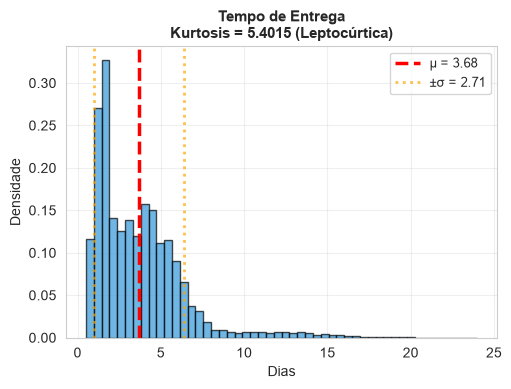

In [28]:
fig = plt.figure(figsize=(20, 14))
gs = fig.add_gridspec(3, 3, hspace=0.35, wspace=0.3)

# Extrair a coluna como Series
tempo = tempo.iloc[:, 0]

# (1) Histogramas com Kurtosis
ax1 = fig.add_subplot(gs[0, 0])

ax1.hist(tempo, bins=50, alpha=0.7, color="#3498db",
         edgecolor="black", density=True)

media = tempo.mean()
dp = tempo.std()

ax1.axvline(media, color="red", linestyle="--",
            linewidth=2.5, label=f"μ = {media:.2f}")

ax1.axvline(media - dp, color="orange", linestyle=":",
            linewidth=2, alpha=0.7)

ax1.axvline(media + dp, color="orange", linestyle=":",
            linewidth=2, alpha=0.7, label=f"±σ = {dp:.2f}")

ax1.set_title(
    f"Tempo de Entrega\nKurtosis = {tempo.kurtosis():.4f} (Leptocúrtica)",
    fontsize=11,
    fontweight="bold"
)

ax1.set_xlabel("Dias")
ax1.set_ylabel("Densidade")
ax1.legend(fontsize=9)
ax1.grid(alpha=0.3)

In [29]:
print(f'Total de registros (Espaço Amostral Ômega): {len(df)}')

Total de registros (Espaço Amostral Ômega): 100000


In [30]:
# probabilidade básica
mediana_tempo = df['Tempo_Entrega_Dias'].median()
entrega_prazo = df['Tempo_Entrega_Dias'] <= mediana_tempo
evento_a = entrega_prazo.sum()

print(f'\nEvento A: Entrega no prazo (<= {mediana_tempo:.2f} dias)')
print(f'|A| = {evento_a} entregas')
print(f'Ômega = {len(df)} entregas')

p_a = evento_a / len(df)
print(f'P(A) = {evento_a} / {len(df)} = {p_a:.4f} ({p_a*100:.2f}%)')


Evento A: Entrega no prazo (<= 3.20 dias)
|A| = 51257 entregas
Ômega = 100000 entregas
P(A) = 51257 / 100000 = 0.5126 (51.26%)


In [31]:
atraso = ~entrega_prazo
evento_a_comp = atraso.sum()

print(f"\nEvento A' (Complementar): Atraso (> {mediana_tempo:.2f} dias)")
print(f"|A'| = {evento_a_comp} entregas")

p_a_comp = evento_a_comp / len(df)
print(f"P(A') = {evento_a_comp} / {len(df)} = {p_a_comp:.4f} = {p_a + p_a_comp:.4f}")

print(f"\nVerificação: P(A) + P(A') = {p_a:.4f} + {p_a_comp:.4f} = {p_a + p_a_comp:.4f}")
print(f"(Deve ser exatamente 1.0 ✓)")

print(f"\nPropriedade: P(A) + P(A') = 1")
print(f"'{p_a:.4f} + {p_a_comp:.4f} = {p_a + p_a_comp:.4f} ✓'")

print("\nSignificado:")
print(f"→ Sempre uma entrega é OU no prazo OU atrasada")
print(f"→ Não existe terceira opção")
print(f"→ Os dois eventos cobrem TODO o espaço amostral")


Evento A' (Complementar): Atraso (> 3.20 dias)
|A'| = 48743 entregas
P(A') = 48743 / 100000 = 0.4874 = 1.0000

Verificação: P(A) + P(A') = 0.5126 + 0.4874 = 1.0000
(Deve ser exatamente 1.0 ✓)

Propriedade: P(A) + P(A') = 1
'0.5126 + 0.4874 = 1.0000 ✓'

Significado:
→ Sempre uma entrega é OU no prazo OU atrasada
→ Não existe terceira opção
→ Os dois eventos cobrem TODO o espaço amostral


In [32]:
regiao_sudeste = df["Regiao_Cliente"] == "Sudeste"
regiao_outras = df["Regiao_Cliente"] != "Sudeste"

evento_b = regiao_sudeste.sum()
evento_c = regiao_outras.sum()

print(f"\nEvento B: Cliente na Sudeste")
print(f"  |B| = {evento_b} entregas")
p_b = evento_b / len(df)
print(f"  P(B) = {p_b:.4f} ({p_b*100:.2f}%)")

print(f"\nEvento C: Cliente em Outra Região")
print(f"  |C| = {evento_c} entregas")
p_c = evento_c / len(df)
print(f"  P(C) = {p_c:.4f} ({p_c*100:.2f}%)")

print(f"\nEventos B e C são MUTUAMENTE EXCLUSIVOS:")
print(f"  → Um cliente NÃO PODE estar em Sudeste E em outra região")
print(f"  → B ∩ C = ∅ (conjunto vazio)")
print(f"  → P(B ∩ C) = 0")

print(f"\nPor isso: P(B ∪ C) = P(B) + P(C)")
print(f"  P(B ∪ C) = {p_b:.4f} + {p_c:.4f} = {p_b + p_c:.4f}")
print(f"(Deve ser 1.0 porque todo cliente está em uma região ✓)")


Evento B: Cliente na Sudeste
  |B| = 39722 entregas
  P(B) = 0.3972 (39.72%)

Evento C: Cliente em Outra Região
  |C| = 60278 entregas
  P(C) = 0.6028 (60.28%)

Eventos B e C são MUTUAMENTE EXCLUSIVOS:
  → Um cliente NÃO PODE estar em Sudeste E em outra região
  → B ∩ C = ∅ (conjunto vazio)
  → P(B ∩ C) = 0

Por isso: P(B ∪ C) = P(B) + P(C)
  P(B ∪ C) = 0.3972 + 0.6028 = 1.0000
(Deve ser 1.0 porque todo cliente está em uma região ✓)


In [33]:
# INTERSECÇÃO DE EVENTOS (A ∩ B)
# Eventos simultâneos: No Prazo E Sudeste

prazo_e_sudeste = entrega_prazo & regiao_sudeste
evento_ab = prazo_e_sudeste.sum()

print(f"\nEvento A ∩ B: Entrega No Prazo E Cliente Sudeste")
print(f"  |A ∩ B| = {evento_ab} entregas")

p_ab = evento_ab / len(df)
print(f"  P(A ∩ B) = {evento_ab} / {len(df)} = {p_ab:.4f} ({p_ab*100:.2f}%)")

print(f"\nSignificado:")
print(f"  → Intersecção = casos que satisfazem AMBAS as condições")
print(f"  → Apenas {evento_ab} entregas foram no prazo E na Sudeste")


Evento A ∩ B: Entrega No Prazo E Cliente Sudeste
  |A ∩ B| = 20449 entregas
  P(A ∩ B) = 20449 / 100000 = 0.2045 (20.45%)

Significado:
  → Intersecção = casos que satisfazem AMBAS as condições
  → Apenas 20449 entregas foram no prazo E na Sudeste


In [34]:
# UNIÃO DE EVENTOS (A U B)
# Eventos: No Prazo OU Sudeste (ou ambos)
prazo_ou_sudeste = entrega_prazo | regiao_sudeste
evento_union = prazo_ou_sudeste.sum()

print(f"\nEvento A U B: Entrega No Prazo OU Cliente Sudeste")
print(f"  |A U B| = {evento_union} entregas")

p_union = p_a + p_b - p_ab
print(f"  P(A U B) = {p_a} + {p_b} - {p_ab} = {p_union:.4f} ({p_union*100:.2f}%)")

print(f"\nSignificado:")
print(f"  -> União = casos que satisfazem PELO MENOS UMA das condições")
print(f"  -> {evento_union} entregas foram no prazo OU na Sudeste (ou ambos)")


Evento A U B: Entrega No Prazo OU Cliente Sudeste
  |A U B| = 70530 entregas
  P(A U B) = 0.51257 + 0.39722 - 0.20449 = 0.7053 (70.53%)

Significado:
  -> União = casos que satisfazem PELO MENOS UMA das condições
  -> 70530 entregas foram no prazo OU na Sudeste (ou ambos)


In [35]:
# Criar Heatmap

In [36]:
# Evento A: Entrega no Prazo
media_tempo = df['Tempo_Entrega_Dias'].mean()
evento_a = df['Tempo_Entrega_Dias'] <= media_tempo
p_a = evento_a.sum() / len(df)

# Evento B: Categoria Eletrônicos
evento_b = df['Categoria_Produto'] == 'Eletrônicos'
p_b = evento_b.sum() / len(df)

# Evento C: Cancelamento
evento_c = df['Cancelamento'] == 'Sim'
p_c = evento_c.sum() / len(df)

In [37]:
print(f'\nEvento A: Entrega no Prazo')
print(f'P(A) = {evento_a.sum():,} / {len(df)} = {p_a:.4f} ({p_a*100:.2f}%)')

print(f'\nEvento B: Categoria Eletrônicos')
print(f'P(B) = {evento_b.sum():,} / {len(df)} = {p_b:.4f} ({p_b*100:.2f}%)')

print(f'\nEvento C: Cancelamento')
print(f'P(C) = {evento_c.sum():,} / {len(df)} = {p_c:.4f} ({p_c*100:.2f}%)')


Evento A: Entrega no Prazo
P(A) = 56,873 / 100000 = 0.5687 (56.87%)

Evento B: Categoria Eletrônicos
P(B) = 24,988 / 100000 = 0.2499 (24.99%)

Evento C: Cancelamento
P(C) = 23,566 / 100000 = 0.2357 (23.57%)


In [38]:
# P(A | B) - Prazo dado Eletrônicos
ab_intersection = (evento_a & evento_b).sum()
p_a_dado_b = ab_intersection / evento_b.sum()

print(f"\n1. P(Prazo | Eletrônicos)")
print(f"    P(A|B) = (Prazo n Eletrônicos) / Eletrônicos")
print(f"           = {ab_intersection:,} / {evento_b.sum():,}")
print(f"           = {p_a_dado_b:.4f} ({p_a_dado_b*100:.2f}%)")

print(f"\n   Comparação:")
print(f"   P(Prazo geral) ........: {p_a:.4f} ({p_a*100:.2f}%)")
print(f"   P(Prazo | Eletrônicos): {p_a_dado_b:.4f} ({p_a_dado_b*100:.2f}%)")

diff_ab = p_a_dado_b - p_a
print(f"   Diferença: {diff_ab:+.4f} ({diff_ab*100:+.2f}%)")
if abs(diff_ab) < 0.02:
    print(f"    ✓ Praticamente IGUAL -> Eventos aproximadamente INDEPENDENTES")
else:
    if diff_ab > 0:
        print(f"    ⚠ Eletrônicos têm MAIS chance no prazo")
    else:
        print(f"    ⚠ Eletrônicos têm MENOS chance no prazo")



1. P(Prazo | Eletrônicos)
    P(A|B) = (Prazo n Eletrônicos) / Eletrônicos
           = 14,196 / 24,988
           = 0.5681 (56.81%)

   Comparação:
   P(Prazo geral) ........: 0.5687 (56.87%)
   P(Prazo | Eletrônicos): 0.5681 (56.81%)
   Diferença: -0.0006 (-0.06%)
    ✓ Praticamente IGUAL -> Eventos aproximadamente INDEPENDENTES


In [39]:
# P(C | B) - Cancelamento dado Eletrônicos
cb_intersection = (evento_c & evento_b).sum()
p_c_dado_b = cb_intersection / evento_b.sum()

print(f"\n2. P(Cancelamento | Eletrônicos)")
print(f"    P(C|B) = (Cancelamento n Eletrônicos) / Eletrônicos")
print(f"           = {cb_intersection:,} / {evento_b.sum():,}")
print(f"           = {p_c_dado_b:.4f} ({p_c_dado_b*100:.2f}%)")

print(f"\n   Comparação:")
print(f"   P(Cancelamento geral) ........: {p_c:.4f} ({p_c*100:.2f}%)")
print(f"   P(Cancelamento | Eletrônicos): {p_c_dado_b:.4f} ({p_c_dado_b*100:.2f}%)")

diff_cb = p_c_dado_b - p_c
print(f"   Diferença: {diff_cb:+.4f} ({diff_cb*100:+.2f}%)")
if abs(diff_cb) < 0.02:
    print(f"    ✓ Praticamente IGUAL -> Eventos aproximadamente INDEPENDENTES")
else:
    if diff_cb > 0:
        print(f"    ⚠ Eletrônicos têm MAIS risco de cancelamento!")
    else:
        print(f"    ⚠ Eletrônicos têm MENOS risco de cancelamento")


2. P(Cancelamento | Eletrônicos)
    P(C|B) = (Cancelamento n Eletrônicos) / Eletrônicos
           = 5,873 / 24,988
           = 0.2350 (23.50%)

   Comparação:
   P(Cancelamento geral) ........: 0.2357 (23.57%)
   P(Cancelamento | Eletrônicos): 0.2350 (23.50%)
   Diferença: -0.0006 (-0.06%)
    ✓ Praticamente IGUAL -> Eventos aproximadamente INDEPENDENTES


In [40]:
print("\n" + "=" * 80)
print("DETECÇÃO DE FRAUDE (SIMULAÇÃO)")
print("=" * 80)

# Simular fraude como padrão de compra: Valor Alto
valor_alto = df["Valor_Total"] > df["Valor_Total"].quantile(0.75)  # Top 25%

#Evento de cancelamento
cancelamento = df["Cancelamento"] == "Sim"

print(f"\nSimulando FRAUDE como padrão: Compra valor muito alto")
print(f"Fraude (valor > percentil 75): {valor_alto.sum():,} casos")

# Assumir correlação entre fraude e cancelamento (maior fraude = mais risco)
p_fraude = valor_alto.sum() / len(df)
p_nao_fraude = 1 - p_fraude

print(f"\nPRIOR (Crença inicial):")
print(f"   P(Fraude) = {p_fraude:.4f} ({p_fraude*100:.2f}%)")

# Verossimilhança: P(Cancelamento | Fraude) e P(Cancelamento | ~Fraude)
p_cancel_dado_fraude = (cancelamento & valor_alto).sum() / valor_alto.sum()
p_cancel_dado_nao_fraude = (cancelamento & ~valor_alto).sum() / (~valor_alto).sum()

print(f"\nVerossimilhança:")
print(f"   P(Cancelamento | Fraude) = {p_cancel_dado_fraude:.4f}")
print(f"   P(Cancelamento | ~Fraude) = {p_cancel_dado_nao_fraude:.4f}")

# Aplicar Bayes para predizer fraude dado cancelamento
p_cancel = cancelamento.sum() / len(df)

p_fraude_dado_cancel = (p_cancel_dado_fraude * p_fraude) / p_cancel

print(f"\nAPLICANDO TEOREMA DE BAYES:")
print(f"   P(Fraude | Cancelamento) = P(Cancel|Fraude) × P(Fraude) / P(Cancel)")
print(f"                            = {p_cancel_dado_fraude:.4f} × {p_fraude:.4f} / {p_cancel:.4f}")
print(f"                            = {p_fraude_dado_cancel:.4f} ({p_fraude_dado_cancel*100:.2f}%)")

print(f"\nCOMPARAÇÃO:")
print(f"   Prior (sem evidência)       : {p_fraude*100:.2f}%")
print(f"   Posterior (com cancelamento): {p_fraude_dado_cancel*100:.2f}%")
print(f"   Aumento                     : {(p_fraude_dado_cancel - p_fraude)*100:+.2f}%")

print(f"\nINTERPRETAÇÃO:")
if p_fraude_dado_cancel > p_fraude * 1.5:
    print(f"    ⚠  Cancelamentos correlacionam muito com fraude!")
    print(f"    Ação: Verificação extra em cancelamentos com valor alto")
else:
    print(f"    ℹ  Cancelamento não indica forte correlação com fraude")


DETECÇÃO DE FRAUDE (SIMULAÇÃO)

Simulando FRAUDE como padrão: Compra valor muito alto
Fraude (valor > percentil 75): 24,997 casos

PRIOR (Crença inicial):
   P(Fraude) = 0.2500 (25.00%)

Verossimilhança:
   P(Cancelamento | Fraude) = 0.2348
   P(Cancelamento | ~Fraude) = 0.2359

APLICANDO TEOREMA DE BAYES:
   P(Fraude | Cancelamento) = P(Cancel|Fraude) × P(Fraude) / P(Cancel)
                            = 0.2348 × 0.2500 / 0.2357
                            = 0.2491 (24.91%)

COMPARAÇÃO:
   Prior (sem evidência)       : 25.00%
   Posterior (com cancelamento): 24.91%
   Aumento                     : -0.09%

INTERPRETAÇÃO:
    ℹ  Cancelamento não indica forte correlação com fraude
